# Week 6 Gaussian Process Suggestions

Fit on observations through Week 5. Use a local heuristic for F2 and Expected Improvement over the configured finite candidate pool for the other functions. The provisional kernel plan uses Rational Quadratic for F1, F3, F5, F6, and F8; RBF for F2; and Matérn 3/2 for F4 and F7. F6 is a prospective RQ test; F7 remains unresolved. Suggestions are model-based and are not guaranteed global optima or measured gains.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.data import save_predictions
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.submission import format_submission
from bayesian_bbo.visualisation import plot_gp_2d, plot_gp_slices

CURRENT_WEEK = 5
NEXT_WEEK = CURRENT_WEEK + 1
FUNCTION_IDS = tuple(FUNCTION_SPECS)
LENGTH_CAPS = CONFIG['length_caps']
ALPHA_VALUES = {1: 0.1, 2: 0.1, 3: 0.2, 4: 0.0, 5: 0.1, 6: 0.1, 7: 0.1, 8: 0.0}
KERNEL_NAMES_BY_FUNCTION = {
    1: 'Rational Quadratic',
    2: 'RBF',
    3: 'Rational Quadratic',
    4: 'Matérn 3/2',
    5: 'Rational Quadratic',
    6: 'Rational Quadratic',
    7: 'Matérn 3/2',
    8: 'Rational Quadratic',
}

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
TRAINING_OBSERVATIONS = {
    function_id: observations.through_week(CURRENT_WEEK)
    for function_id, observations in history.observations.items()
}
XI_VALUES = {
    function_id: ALPHA_VALUES[function_id] * np.std(TRAINING_OBSERVATIONS[function_id].outputs)
    for function_id in FUNCTION_IDS
}
print(f'Training cutoff: week {CURRENT_WEEK}; exporting week {NEXT_WEEK}')
print(f'Configured candidate pool: {CONFIG["candidates"]:,} per function')
print(f'Data root: {data_root}')
print(f'Kernel map: {KERNEL_NAMES_BY_FUNCTION}')

Training cutoff: week 5; exporting week 6
Configured candidate pool: 1,000,000 per function
Data root: /home/pabloncho/repositories/bayesian-bbo/data
Kernel map: {1: 'Rational Quadratic', 2: 'RBF', 3: 'Rational Quadratic', 4: 'Matérn 3/2', 5: 'Rational Quadratic', 6: 'Rational Quadratic', 7: 'Matérn 3/2', 8: 'Rational Quadratic'}


## 1. Candidate selection

Use the provisional per-function kernel plan from the surrogate diagnostics. For F2, test $(0.712637, 0.926564)$: increase the incumbent's first coordinate by 0.01 while holding the second fixed. This is a local heuristic, not the EI pool maximum. Other functions use EI pool selection. The EI score at each chosen point uses $\xi=\alpha\,\mathrm{std}(y)$ and the current incumbent.

In [2]:
HEURISTIC_CANDIDATES = {
    2: (0.712637, 0.926564),
}
unknown_functions = set(HEURISTIC_CANDIDATES) - set(FUNCTION_IDS)
if unknown_functions:
    raise ValueError(f'Unsupported heuristic function IDs: {sorted(unknown_functions)}')

optimizers = {}
candidate_records = []
for function_id in FUNCTION_IDS:
    observations = TRAINING_OBSERVATIONS[function_id]
    kernel_name = KERNEL_NAMES_BY_FUNCTION[function_id]
    kernel = make_comparison_kernels(
        observations.dimension, LENGTH_CAPS[function_id],
    )[kernel_name]
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(
            budget=1, candidates=CONFIG['candidates'], kernel=kernel, xi=XI_VALUES[function_id],
        ),
    )
    if function_id in HEURISTIC_CANDIDATES:
        candidate = np.asarray(HEURISTIC_CANDIDATES[function_id], dtype=float)
        if (candidate.shape != (observations.dimension,) or not np.all(np.isfinite(candidate))
                or np.any((candidate < 0) | (candidate >= 1))):
            raise ValueError(f'Function {function_id}: invalid heuristic candidate')
        if np.any(np.all(observations.inputs == candidate, axis=1)):
            raise ValueError(f'Function {function_id}: heuristic point has already been evaluated')
        means, stds, scores = optimizer.predict(candidate.reshape(1, -1))
        mean, std, score = float(means[0]), float(stds[0]), float(scores[0])
        selection_method = 'local heuristic'
    else:
        candidate, mean, std, score = optimizer.suggest_with_prediction()
        selection_method = 'EI pool maximum'
    if np.any(np.all(observations.inputs == candidate, axis=1)):
        raise ValueError(f'Function {function_id}: optimizer suggested an already evaluated input')
    optimizers[function_id] = optimizer
    candidate_records.append({
        'function_id': function_id,
        'kernel': kernel_name,
        'selection_method': selection_method,
        'alpha': ALPHA_VALUES[function_id],
        'xi': XI_VALUES[function_id],
        'candidate': tuple(candidate),
        'submission': format_submission(candidate),
        'expected_mean': mean,
        'expected_std': std,
        'expected_ei': score,
        'previous_best': observations.best_output,
    })
next_candidates = pd.DataFrame(candidate_records)
display(next_candidates)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a b

,function_id,kernel,selection_method,alpha,xi,candidate,submission,expected_mean,expected_std,expected_ei,previous_best
0,1,Rational Quadratic,EI pool maximum,0.1,0.000090,"(0.77373, 0.763077)",0.773730-0.763077,-0.000039,0.000806,0.000259,0.000006
1,2,RBF,local heuristic,0.1,0.023998,"(0.712637, 0.926564)",0.712637-0.926564,0.572913,0.026643,0.000087,0.611205
2,3,Rational Quadratic,EI pool maximum,0.2,0.015736,"(0.392553, 0.473772, 0.496042)",0.392553-0.473772-0.496042,0.012634,0.047544,0.020397,-0.005895
3,4,Matérn 3/2,EI pool maximum,0.0,0.000000,"(0.37202, 0.381747, 0.406424, 0.396711)",0.372020-0.381747-0.406424-0.396711,0.434003,0.470675,0.087757,0.687027
4,5,Rational Quadratic,EI pool maximum,0.1,158.103382,"(0.999317, 0.988415, 0.993298, 0.955076)",0.999317-0.988415-0.993298-0.955076,7249.598409,101.275657,15.856375,7156.856542
5,6,Rational Quadratic,EI pool maximum,0.1,0.051537,"(0.483903, 0.337689, 0.522437, 0.776108, 0.145...",0.483903-0.337689-0.522437-0.776108-0.145322,-0.389958,0.106735,0.056542,-0.466997
6,7,Matérn 3/2,EI pool maximum,0.1,0.066166,"(0.013554, 0.001575, 0.52328, 0.310908, 0.2958...",0.013554-0.001575-0.523280-0.310908-0.295869-0...,2.009686,0.242663,0.003943,2.367723
7,8,Rational Quadratic,EI pool maximum,0.0,0.000000,"(0.060407, 0.148811, 0.140889, 0.174148, 0.664...",0.060407-0.148811-0.140889-0.174148-0.664420-0...,10.094976,0.081316,0.202186,9.892961


## 2. GP diagnostics at the selected candidates

Markers use the optimizer-returned candidate mean, standard deviation, and EI. Slice curves are conditional one-coordinate views through the candidate, not projections over other coordinates.

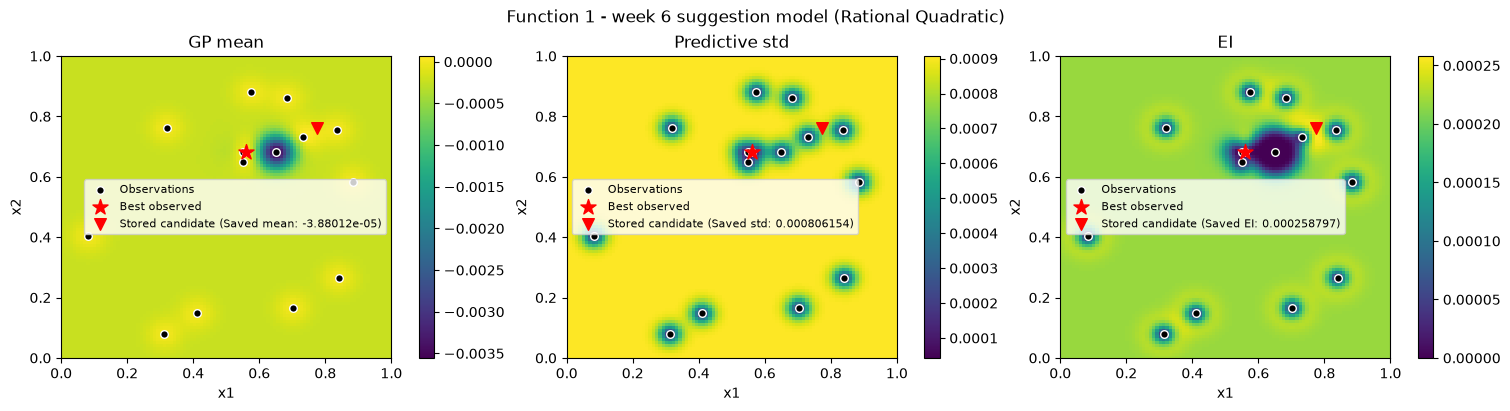

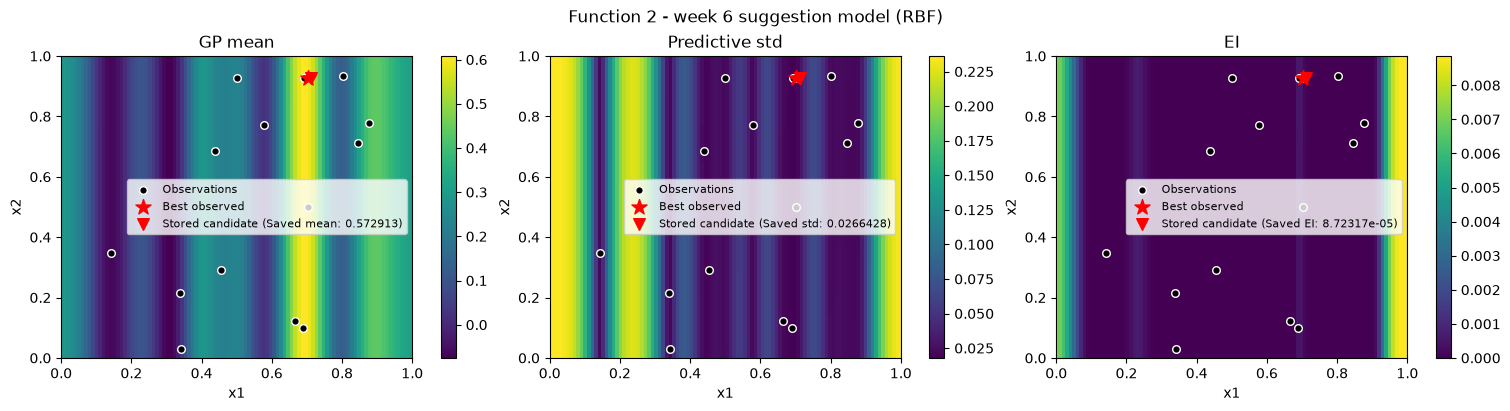

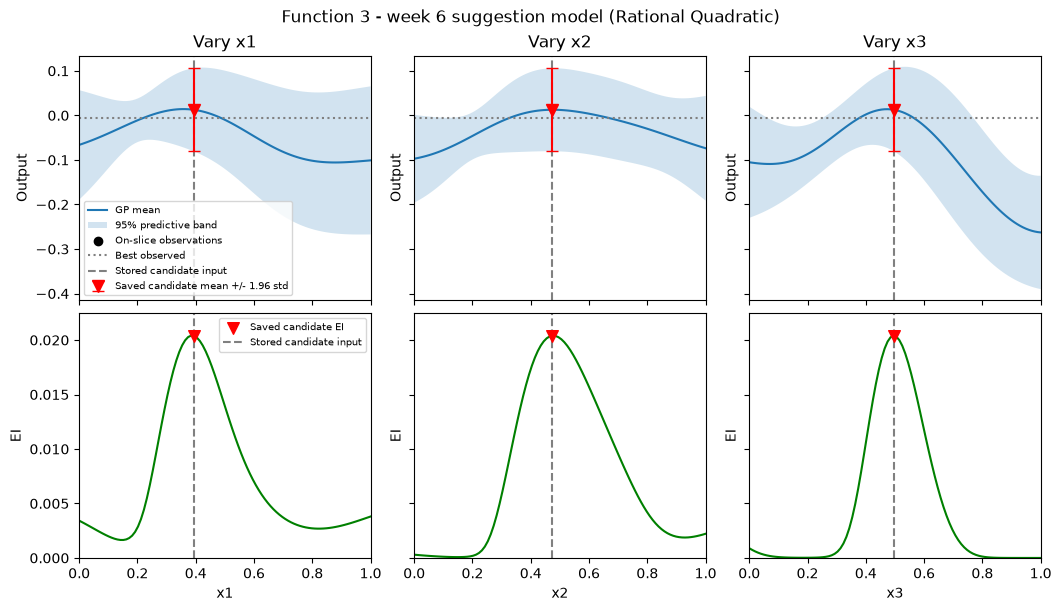

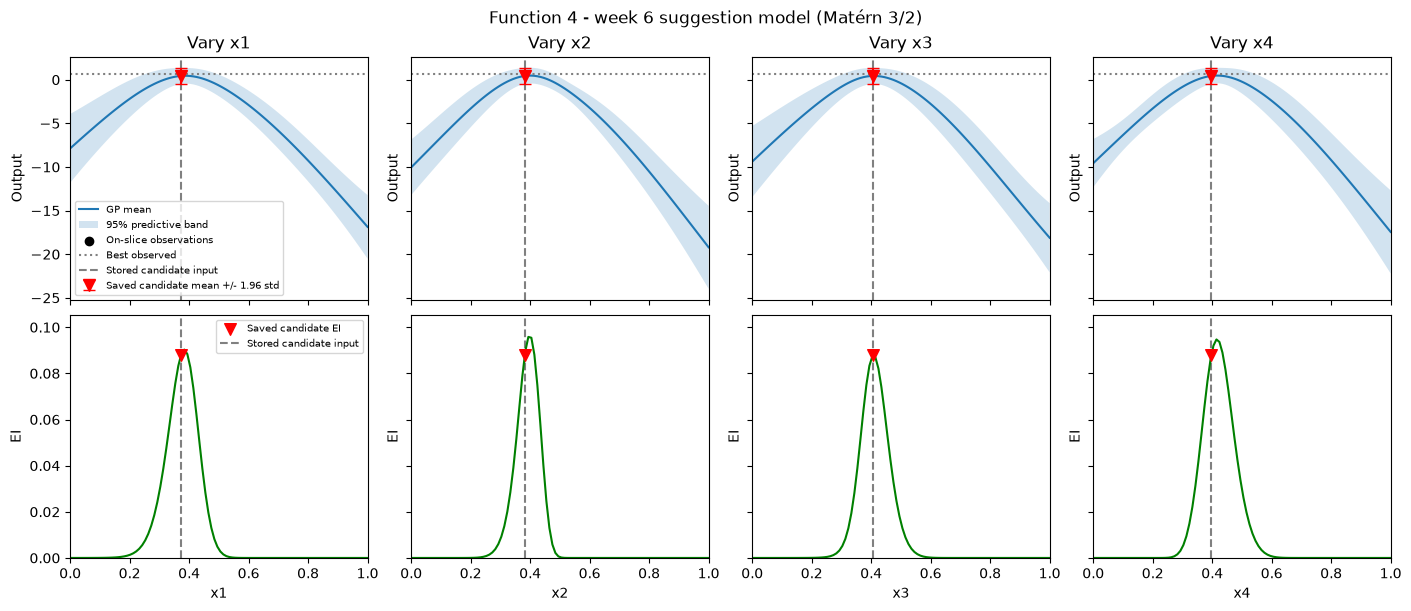

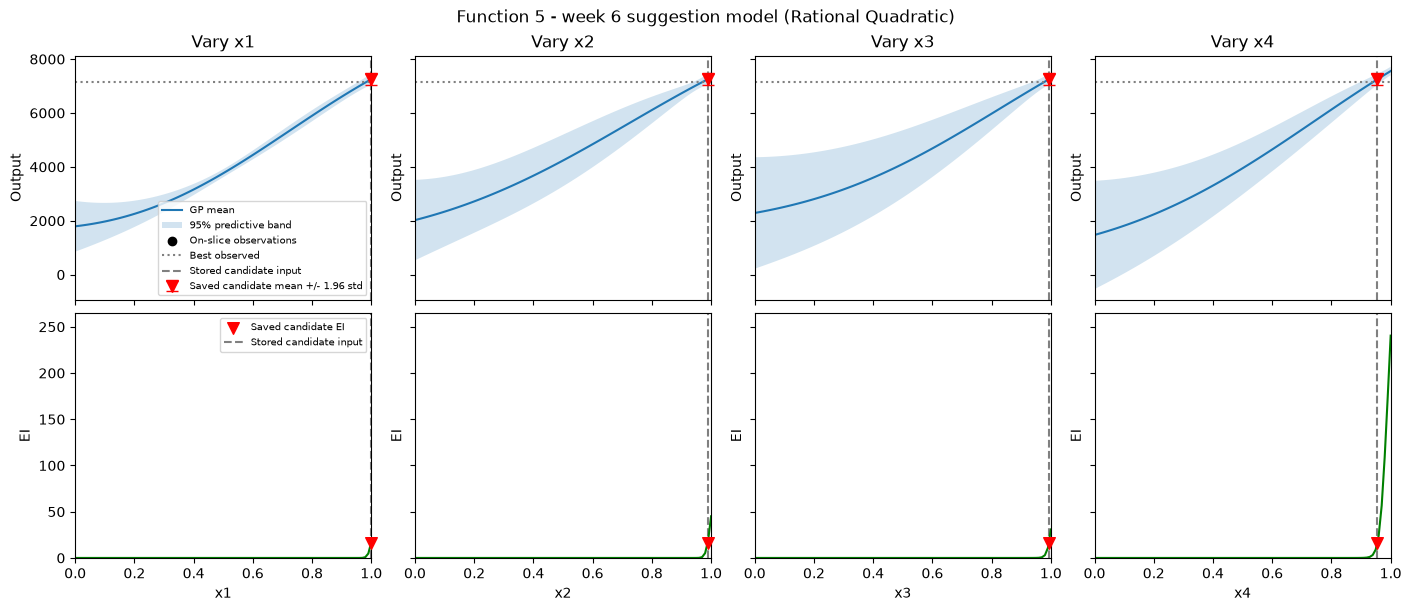

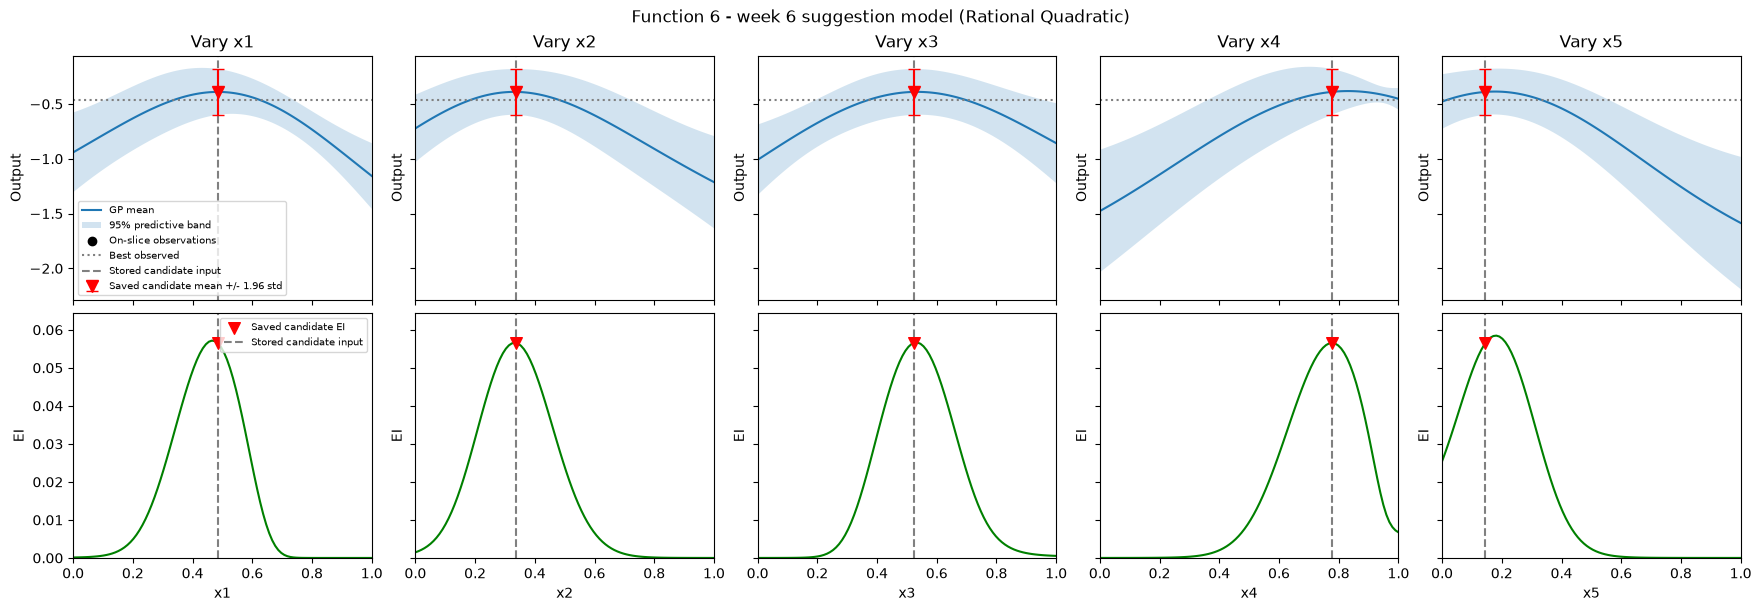

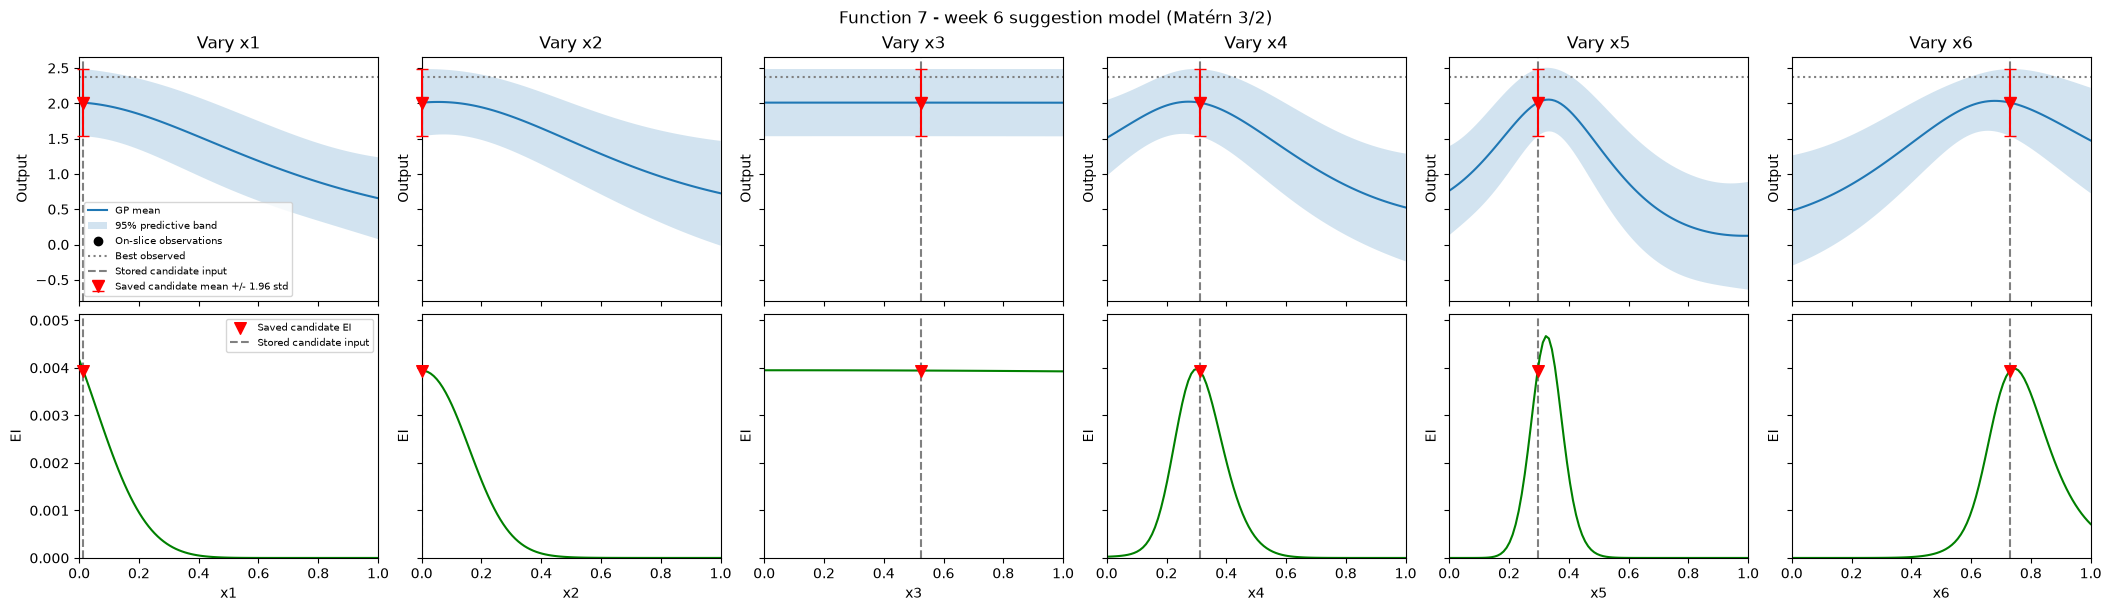

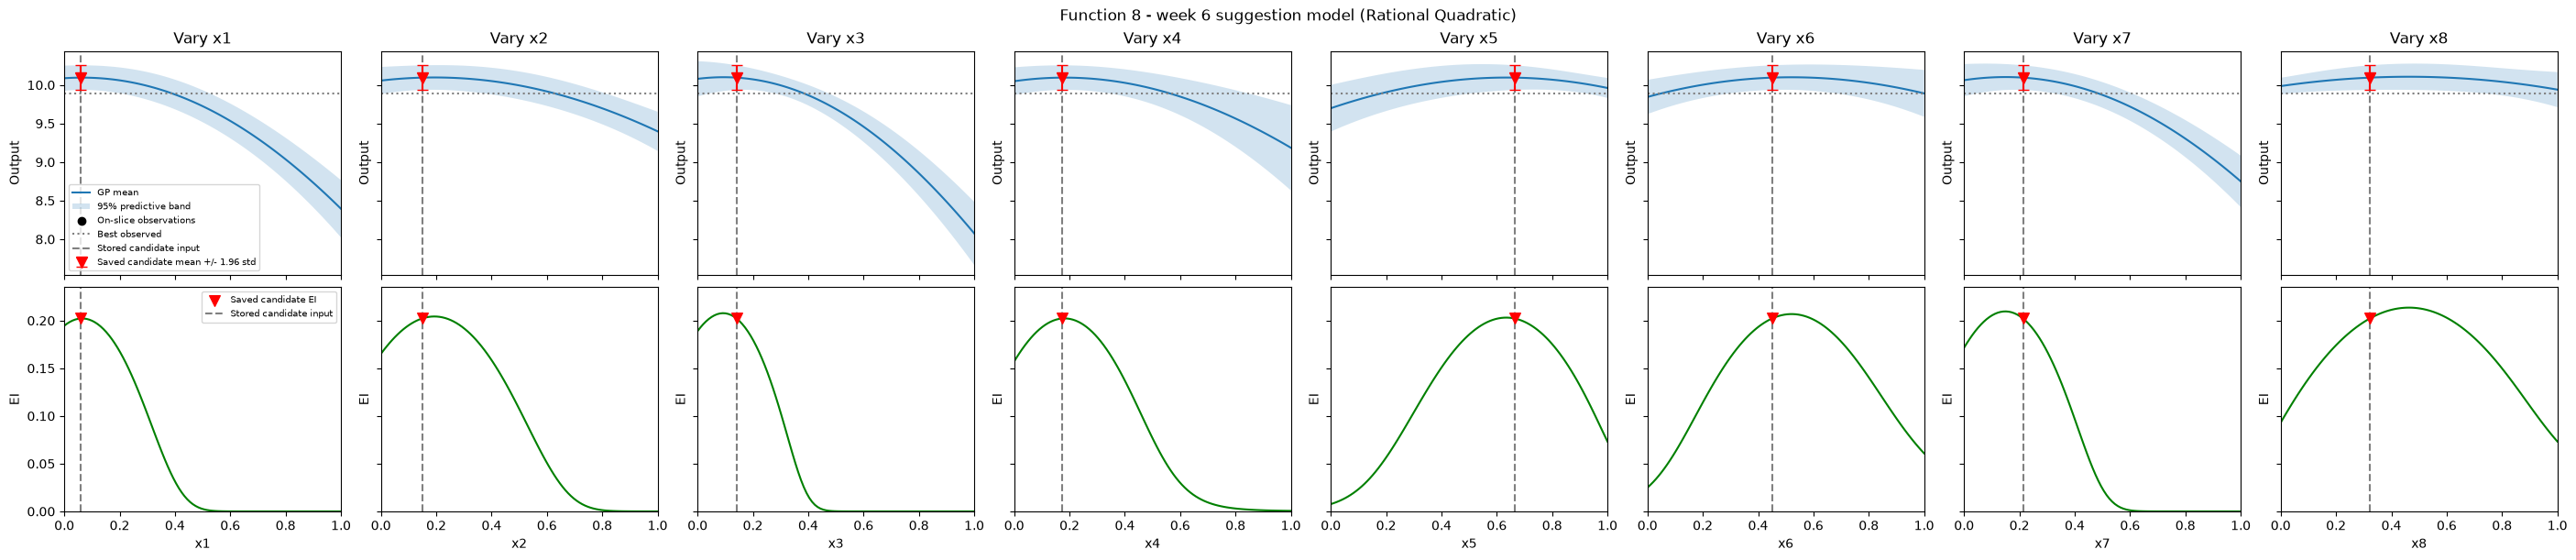

In [3]:
for row in candidate_records:
    function_id = row['function_id']
    observations = TRAINING_OBSERVATIONS[function_id]
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, axes = plot(
        optimizers[function_id], n=100,
        candidate=row['candidate'],
        expected_mean=row['expected_mean'], expected_std=row['expected_std'],
        expected_ei=row['expected_ei'],
    )
    title = f'Function {function_id} - week {NEXT_WEEK} suggestion model ({row["kernel"]})'
    if observations.dimension == 2:
        grid_max = next((artist for artist in axes[2].collections
                         if artist.get_label() == 'Grid EI max'), None)
        if grid_max is not None:
            x1, x2 = grid_max.get_offsets()[0]
            title += f'\nGrid EI max: ({x1:.6f}, {x2:.6f})'
    figure.suptitle(title)
    display(figure)
    plt.close(figure)

## 3. Export Week 6 predictions

Save the six-decimal candidate coordinates and matching pre-evaluation mean, standard deviation, expected-best value, EI score, and incumbent settings. The Week 6 exports were intentionally replaced with the revised candidates after approval. Further differing replacements require explicit approval. Week 5 observations and earlier evaluated data remain unchanged.

In [4]:
export_rows = next_candidates.sort_values('function_id').reset_index(drop=True)
if export_rows.function_id.tolist() != list(FUNCTION_IDS):
    raise ValueError('Export requires exactly one candidate per function in function order.')

submission_points = export_rows[['function_id', 'submission']]
with pd.option_context('display.max_colwidth', None):
    display(submission_points)

suggested_points = [[float(value) for value in text.split('-')] for text in export_rows.submission]
if suggested_points != [list(point) for point in export_rows.candidate]:
    raise ValueError('Exported coordinates differ from the points used for predictions.')
best_outputs = [TRAINING_OBSERVATIONS[function_id].best_output for function_id in FUNCTION_IDS]

week_directory = data_root / 'weekly_updates' / f'week_{NEXT_WEEK}'
saved_prediction_paths = save_predictions(
    export_rows.expected_mean.tolist(),
    suggested_points,
    export_rows.expected_std.tolist(),
    best_outputs,
    week_directory,
    acquisition_scores=export_rows.expected_ei.tolist(),
    acquisition_settings=[
        {'name': 'ei', 'xi': float(xi), 'best': float(best)}
        for xi, best in zip(export_rows.xi, best_outputs)
    ],
    overwrite=True,
)
saved_prediction_paths

,function_id,submission
0,1,0.773730-0.763077
1,2,0.712637-0.926564
2,3,0.392553-0.473772-0.496042
3,4,0.372020-0.381747-0.406424-0.396711
4,5,0.999317-0.988415-0.993298-0.955076
5,6,0.483903-0.337689-0.522437-0.776108-0.145322
6,7,0.013554-0.001575-0.523280-0.310908-0.295869-0.730409
7,8,0.060407-0.148811-0.140889-0.174148-0.664420-0.450375-0.212793-0.322075


Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_6/inputs.json
Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_6/predictions.json


{'inputs.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_6/inputs.json'),
 'predictions.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_6/predictions.json')}